## 02. Neural Network classification with PyTorch

Classification is the problem of predicting whether something is one thing or another (there can be multiple things as the options).

## Import Libraries 

In [32]:
import torch 
import torch.nn as nn 
print(torch.__version__)

from sklearn.model_selection import train_test_split

2.14.1+cu130


In [18]:
from sklearn.datasets import make_circles

X, y = make_circles(
    n_samples=1000,
    shuffle=True,
    noise=0.04,
    random_state=42
)

In [19]:
len(X), len(y)

(1000, 1000)

In [20]:
print(f"First Five samples of X:\n  {X[:5]}")
print(f"First Five samples of y:\n  {y[:5]}")

First Five samples of X:
  [[ 0.74822656  0.23908325]
 [-0.74509559  0.16097526]
 [-0.82262532  0.19762051]
 [-0.41143316  0.68255648]
 [ 0.44390494 -0.89582949]]
First Five samples of y:
  [1 1 1 1 0]


In [21]:
# Make DataFrame of circle data 

import pandas as pd 
circles = pd.DataFrame({"X1":X[:, 0],
                       "X2":X[:, 1],
                       "Label": y })

In [22]:
circles.head()

,X1,X2,Label
0,0.748227,0.239083,1
1,-0.745096,0.160975,1
2,-0.822625,0.197621,1
3,-0.411433,0.682556,1
4,0.443905,-0.895829,0


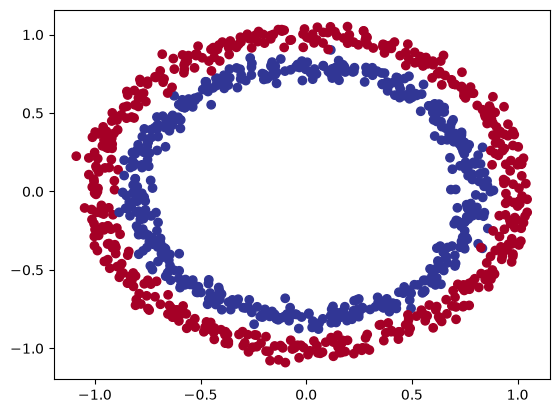

In [23]:
# Visualize

import matplotlib.pyplot as plt

plt.scatter(x=X[:,0],
            y=X[:, 1],
            c=y,
            cmap=plt.cm.RdYlBu)
plt.show()

 # 1.1 Check input and outputs shapes 

In [24]:
X.shape, y.shape

((1000, 2), (1000,))

In [25]:
# view the first example of the features and labels 

x_sample = X[0]

y_sample = y[0]

print(f"Values for one sample of X: {x_sample} and the same for y: {y_sample}")
print(f"Shapes for one sample of X: {x_sample.shape} and the same for y: {y_sample.shape}")

Values for one sample of X: [0.74822656 0.23908325] and the same for y: 1
Shapes for one sample of X: (2,) and the same for y: ()


### 1.2 Trun data into tensors and create train and test splits 

In [27]:
# Check the data type of the x 
type(X)

numpy.ndarray

In [28]:
# Convert data into the tensors 

X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

In [30]:
X.type(), y.type()

('torch.FloatTensor', 'torch.FloatTensor')

In [31]:
X[:5], y[:5]

(tensor([[ 0.7482,  0.2391],
         [-0.7451,  0.1610],
         [-0.8226,  0.1976],
         [-0.4114,  0.6826],
         [ 0.4439, -0.8958]]),
 tensor([1., 1., 1., 1., 0.]))

### Split data into training and test sets

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2, # 20% is testing data and remaning is Training data 
                                                    random_state=42,
                                                    stratify=y)

In [35]:
len(X_train), len(X_test) , len(y_train), len(y_test)

(800, 200, 800, 200)

### Setup Devices

In [36]:
if torch.cuda.is_available():
    device = "cuda"

else: 
    device = "cpu"


print("Device", device)

Device cuda


## 2. Building a model 